# 10 | CASALS versus 3DEP elevation reference audit

This notebook applies a strict evidence gate before any absolute elevation comparison. It audits both available CASALS L1B granules and their paired 3DEP LAZ files. The current result is **BLOCKED**: missing source-frame and Z-processing evidence prevents a reliable vertical comparison. The notebook records the blockers and does not reconstruct ground surfaces or compute elevation residuals.

The H5 Refh convention is treated as nominal WGS84 ellipsoidal height only for operation discovery. Source realization, coordinate epoch, and processor corrections remain unresolved. The LAS headers declare 2D horizontal EPSG:6347; the headers do not define a vertical CRS.


In [1]:
from pathlib import Path
import json, re, sys, warnings
import h5py
import laspy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display, Image
from pyproj import CRS
from pyproj.aoi import AreaOfInterest
from pyproj.transformer import TransformerGroup
import pyproj

ROOT = Path.cwd()
if not (ROOT / "casals_l1b").is_dir():
    raise RuntimeError("Start Jupyter from the CASALS repository root.")
sys.path.insert(0, str(ROOT))
from research.l1b_validation import reference_readiness

H5_DIR = ROOT / "data/raw/casals_l1b"
LAZ_DIR = ROOT / "data/reference/3dep"
OUTPUT_DIR = ROOT / "outputs/notebooks/10_3dep_elevation_validation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
H5_PATHS = sorted(H5_DIR.glob("casals_l1b_202411*T*_001_02.h5"))
if len(H5_PATHS) != 2:
    raise FileNotFoundError(f"Expected two CASALS L1B H5 granules; found {len(H5_PATHS)}")

source_crs_assumption = CRS.from_epsg(4979)  # discovery only; not a verified CASALS source frame
reference_target_crs = CRS.from_user_input("EPSG:6347+5703")
reference_records = []
for h5_path in H5_PATHS:
    laz_matches = sorted(LAZ_DIR.glob(f"{h5_path.stem}_*.laz"))
    if len(laz_matches) != 1:
        raise FileNotFoundError(f"Expected one paired 3DEP LAZ for {h5_path.name}; found {len(laz_matches)}")
    laz_path = laz_matches[0]
    sidecar_candidates = [
        laz_path.with_suffix(laz_path.suffix + ".json"),
        laz_path.with_suffix(".json"),
        ROOT / "outputs/reference_crs_validation" / f"{h5_path.stem}_summary.json",
        ROOT / "outputs/reference_crs_validation" / f"{laz_path.stem}_summary.json",
    ]
    sidecars = [str(p.relative_to(ROOT)) for p in sidecar_candidates if p.is_file()]
    with h5py.File(h5_path, "r") as h5:
        n_pulses = int(h5["rx_waveform"].shape[0])
        h5_attrs = {str(k): str(v.decode("utf-8", "replace") if isinstance(v, bytes) else v) for k, v in h5.attrs.items()}
        height_attrs = {}
        for name in ("refh", "refh_longitude", "refh_latitude"):
            height_attrs[name] = {str(k): str(v.decode("utf-8", "replace") if isinstance(v, bytes) else v) for k, v in h5[name].attrs.items()}
        frame_attr_pattern = re.compile(r"crs|datum|epoch|ellipsoid|vertical|height|geodetic", re.I)
        h5_frame_attrs = {k: v for k, v in h5_attrs.items() if frame_attr_pattern.search(k)}
        refh_lon = np.asarray(h5["refh_longitude"][:], dtype=np.float64)
        refh_lat = np.asarray(h5["refh_latitude"][:], dtype=np.float64)
    finite_geodetic = np.isfinite(refh_lon) & np.isfinite(refh_lat)
    if not np.any(finite_geodetic):
        raise RuntimeError(f"No finite H5 nominal longitude/latitude in {h5_path.name}")
    aoi_padding_deg = 0.01
    aoi_bounds = [
        float(np.nanmin(refh_lon[finite_geodetic]) - aoi_padding_deg),
        float(np.nanmin(refh_lat[finite_geodetic]) - aoi_padding_deg),
        float(np.nanmax(refh_lon[finite_geodetic]) + aoi_padding_deg),
        float(np.nanmax(refh_lat[finite_geodetic]) + aoi_padding_deg),
    ]
    del refh_lon, refh_lat, finite_geodetic
    with laspy.open(laz_path) as reader:
        header = reader.header
        las_crs = header.parse_crs(prefer_wkt=True)
        if las_crs is None:
            raise RuntimeError(f"Could not parse LAS CRS from {laz_path.name}")
        horizontal_epsg = las_crs.to_epsg()
        horizontal_axis_count = len(las_crs.axis_info)
        las_header = {
            "point_count": int(header.point_count),
            "version": str(header.version),
            "point_format": int(header.point_format.id),
            "horizontal_epsg": horizontal_epsg,
            "crs_wkt": las_crs.to_wkt(),
            "crs_axis_count": horizontal_axis_count,
            "has_vertical_axis_in_header": bool(las_crs.is_compound or horizontal_axis_count >= 3),
            "xy_bounds": {"xmin": float(header.mins[0]), "ymin": float(header.mins[1]), "xmax": float(header.maxs[0]), "ymax": float(header.maxs[1])},
            "z_bounds_header_only": {"zmin": float(header.mins[2]), "zmax": float(header.maxs[2])},
            "z_scale": float(header.scales[2]),
            "z_offset": float(header.offsets[2]),
            "vlr_ids": [{"user_id": str(v.user_id), "record_id": int(v.record_id), "description": str(v.description)} for v in list(header.vlrs) + list(header.evlrs or [])],
        }
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        group = TransformerGroup(
            source_crs_assumption,
            reference_target_crs,
            always_xy=True,
            area_of_interest=AreaOfInterest(*aoi_bounds),
            allow_ballpark=False,
        )
    missing_grids = sorted({str(grid.short_name) for op in group.unavailable_operations for grid in op.grids if not grid.available})
    h5_frame_complete = bool(h5_frame_attrs) and any("realization" in k.lower() for k in h5_frame_attrs) and any("epoch" in k.lower() for k in h5_frame_attrs)
    evidence = {
        "casals_horizontal_reference_verified": False,
        "casals_vertical_reference_verified": False,
        "reference_horizontal_crs_verified": horizontal_epsg == 6347,
        "reference_vertical_frame_verified": las_header["has_vertical_axis_in_header"],
        "historical_z_processing_verified": False,
        "reference_source_provenance_verified": bool(sidecars),
        "best_required_transform_available": bool(group.best_available and group.transformers),
    }
    readiness = reference_readiness(evidence)
    record = {
        "granule": h5_path.stem,
        "h5_path": str(h5_path.relative_to(ROOT)),
        "laz_path": str(laz_path.relative_to(ROOT)),
        "h5_n_pulses": n_pulses,
        "h5_frame_attribute_names": sorted(h5_frame_attrs),
        "h5_geodetic_frame_claim_complete": bool(h5_frame_complete),
        "h5_frame_attributes": h5_frame_attrs,
        "h5_relevant_dataset_attributes": height_attrs,
        "reference_sidecars_found": sidecars,
        "reference_sidecar_candidates": [str(p.relative_to(ROOT)) for p in sidecar_candidates],
        "las_header": las_header,
        "candidate_transform_audit": {
            "source_assumption_epsg": 4979,
            "target_epsg_compound": "EPSG:6347+5703",
            "always_xy": True,
            "allow_ballpark": False,
            "area_of_interest_wgs84_degrees": {"west": aoi_bounds[0], "south": aoi_bounds[1], "east": aoi_bounds[2], "north": aoi_bounds[3]},
            "area_of_interest_padding_degrees": aoi_padding_deg,
            "applied": False,
            "best_available": bool(group.best_available),
            "available_non_ballpark_transformer_count": len(group.transformers),
            "available_operations": [{"description": t.description, "accuracy_m": float(t.accuracy), "pipeline": t.definition} for t in group.transformers],
            "unavailable_operation_count": len(group.unavailable_operations),
            "unavailable_operations": [{"name": op.name, "method_name": op.method_name, "accuracy_m": float(op.accuracy), "grids": [{"short_name": grid.short_name, "available": bool(grid.available), "url": grid.url} for grid in op.grids]} for op in group.unavailable_operations],
            "missing_grid_short_names": missing_grids,
            "pyproj_version": pyproj.__version__,
            "proj_version": pyproj.proj_version_str,
            "warnings": [str(item.message) for item in caught],
        },
        "evidence": evidence,
        "readiness": readiness,
        "absolute_elevation_errors_computed": False,
        "casals_frame_status": "unresolved",
        "reference_frame_evidence_sources": {
            "h5": str(h5_path.relative_to(ROOT)),
            "las_laz_header": str(laz_path.relative_to(ROOT)),
            "sidecar_candidates_found": sidecars,
            "sidecar_candidates_missing": [str(p.relative_to(ROOT)) for p in sidecar_candidates if not p.is_file()],
            "repository_context_document_not_primary_evidence": "docs/3dep_reference.md",
        },
        "ground_surface_reconstruction_status": "not_run: reference frame gate is BLOCKED",
        "empirical_vertical_shift_applied": False,
    }
    reference_records.append(record)

print(f"Audited {len(reference_records)} paired H5/LAZ inputs. No waveform cube or full LAZ point cloud was loaded.")
display(pd.DataFrame([{
    "granule": r["granule"],
    "H5 pulses": r["h5_n_pulses"],
    "LAS horizontal EPSG": r["las_header"]["horizontal_epsg"],
    "LAS vertical axis": r["las_header"]["has_vertical_axis_in_header"],
    "sidecars found": len(r["reference_sidecars_found"]),
    "best transform available": r["candidate_transform_audit"]["best_available"],
    "status": r["readiness"]["status"],
    "blockers": "; ".join(x["code"] for x in r["readiness"]["blockers"]),
} for r in reference_records]))


Audited 2 paired H5/LAZ inputs. No waveform cube or full LAZ point cloud was loaded.


,granule,H5 pulses,LAS horizontal EPSG,LAS vertical axis,sidecars found,best transform available,status,blockers
0,casals_l1b_20241112T165718_001_02,3604480,6347,False,0,False,BLOCKED,CASALS_HORIZONTAL_FRAME_UNVERIFIED; CASALS_VER...
1,casals_l1b_20241118T171757_001_02,3604480,6347,False,0,False,BLOCKED,CASALS_HORIZONTAL_FRAME_UNVERIFIED; CASALS_VER...


## Interpretation

`EPSG:6347` identifies a horizontal NAD83(2011) / UTM zone 18N CRS. It does not identify the vertical reference of LAS Z. The current H5 metadata does not verify a complete CASALS geodetic source frame, and neither LAS header contains a vertical CRS. The original source/work-unit sidecars and historical clip-Z audit are absent from this workspace.

PROJ operation discovery uses a non-ballpark EPSG:4979 source assumption, explicit `EPSG:6347+5703` compound target, `always_xy=True`, and a recorded AOI derived from each H5 nominal coordinate extent with a 0.01-degree margin. This is an operation-availability audit only: no transformer is applied. The record includes available/unavailable operations, grid availability, PROJ versions, and candidate pipelines.

The status is **BLOCKED** for both granules. This work produces only the reference-frame audit and explicit blockers. It does not reconstruct a 3DEP ground surface, calculate raw or centered height differences, or report absolute/relative elevation accuracy. No empirical `dz` is fitted or applied.

Evidence needed to reopen the gate: authoritative CASALS source realization/epoch and height-processing documentation; preserved 3DEP work-unit vertical metadata and source provenance; verified historical clip-Z behavior; and an available, audited non-ballpark XYZ operation with required grids. The repository's 3DEP note is contextual documentation, not a substitute for missing source sidecars.

A separate synthetic unit test checks a known EPSG:4979-to-EPSG:4978 XYZ transform and its inverse round trip. It validates helper mechanics only; it does not validate or apply a transform for these granules.


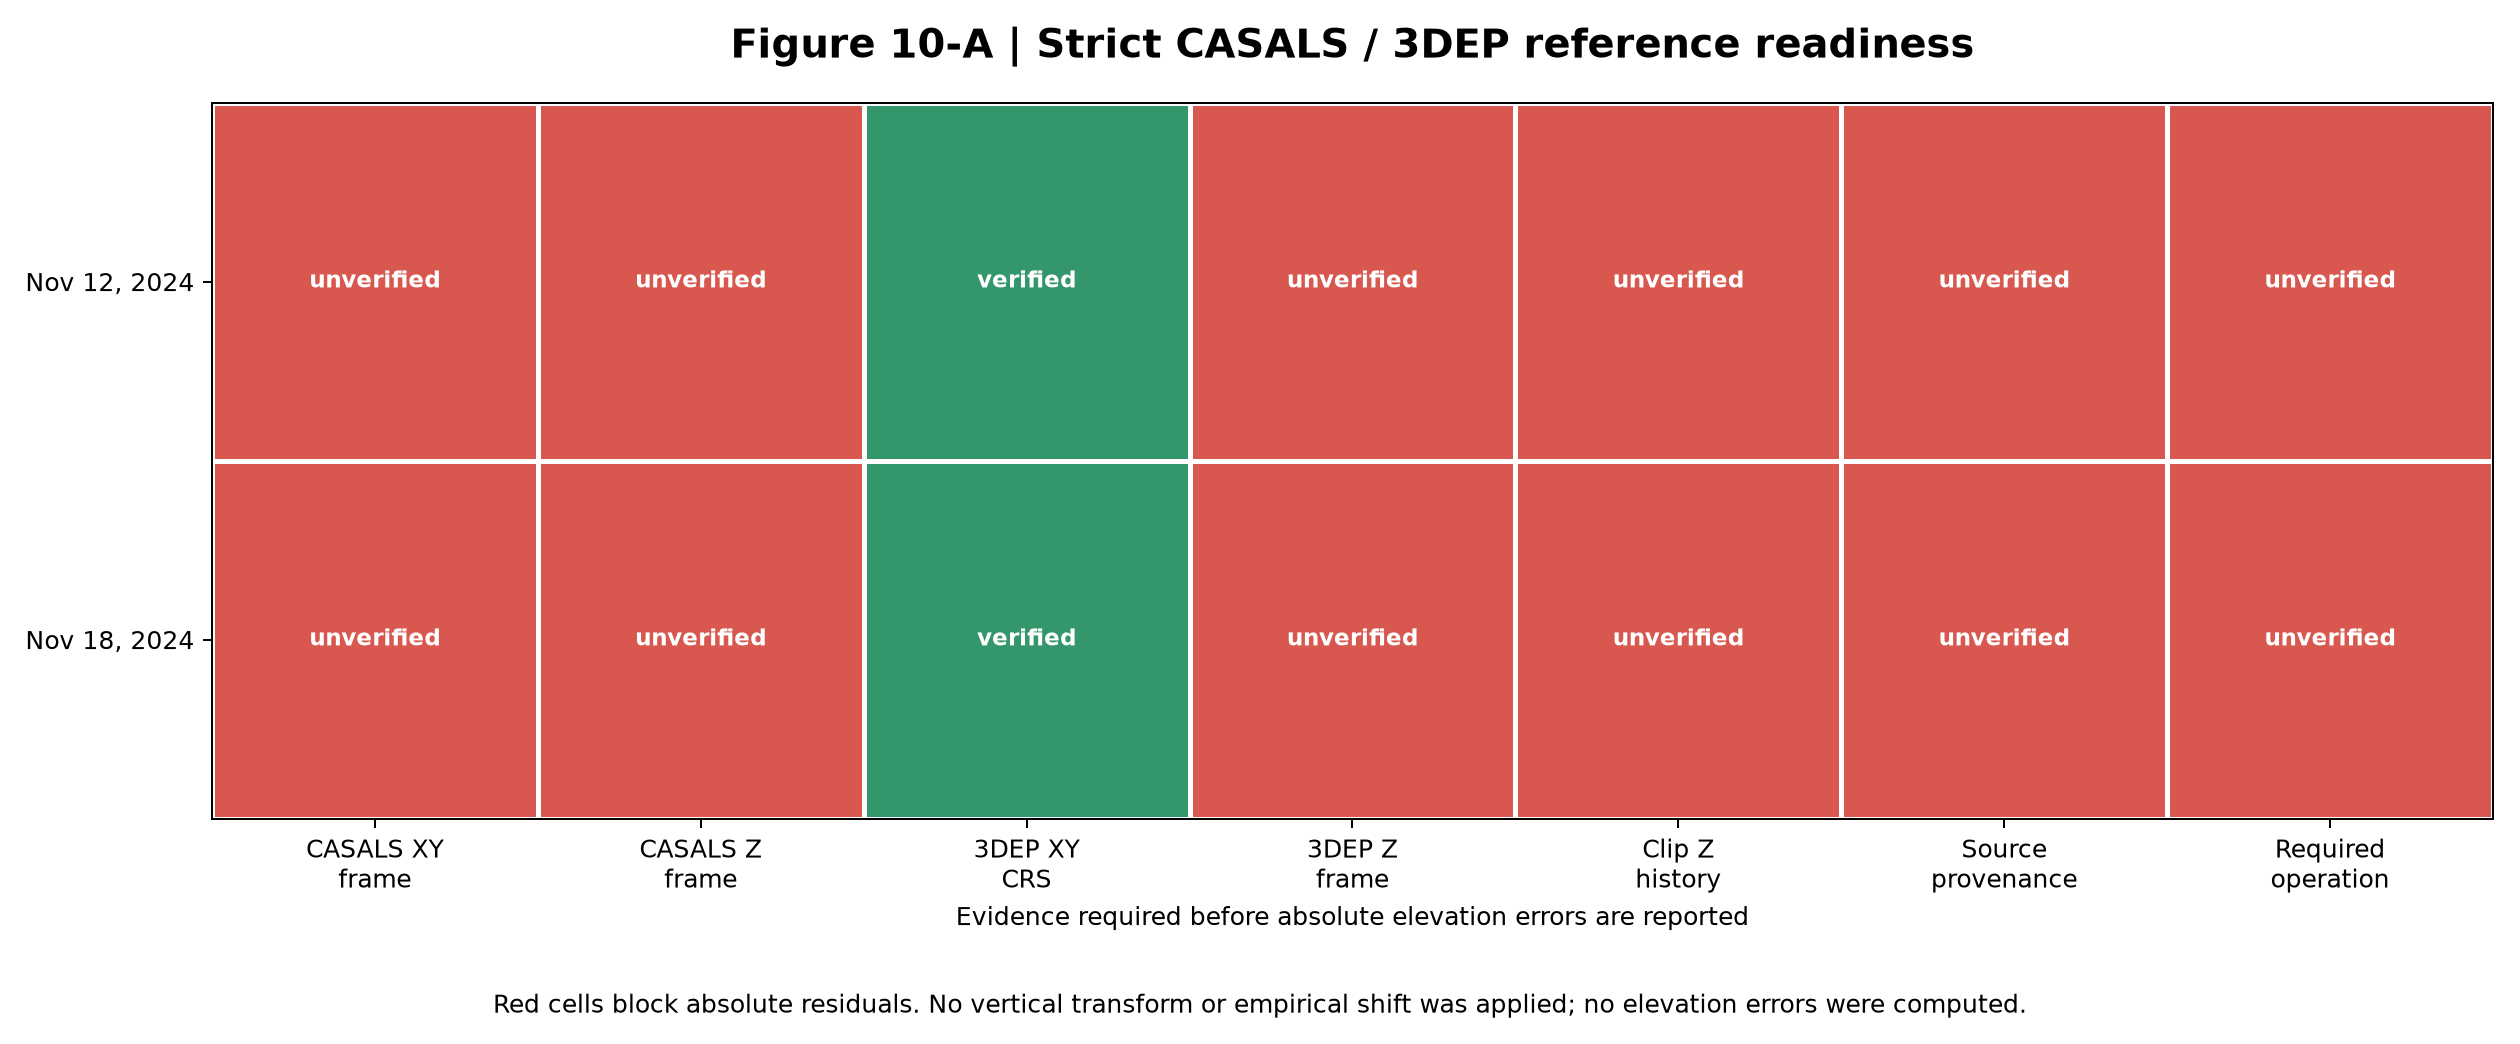

,granule,status,blocker_codes,absolute_errors_computed
0,casals_l1b_20241112T165718_001_02,BLOCKED,CASALS_HORIZONTAL_FRAME_UNVERIFIED;CASALS_VERT...,False
1,casals_l1b_20241118T171757_001_02,BLOCKED,CASALS_HORIZONTAL_FRAME_UNVERIFIED;CASALS_VERT...,False


In [2]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display, Image

out_json = OUTPUT_DIR / "reference_frame_audit.json"
out_json.write_text(json.dumps(reference_records, indent=2, allow_nan=False), encoding="utf-8")
rows = []
for r in reference_records:
    rows.append({
        "granule": r["granule"],
        "status": r["readiness"]["status"],
        "absolute_elevation_errors_permitted": r["readiness"]["absolute_elevation_errors_permitted"],
        "h5_pulses": r["h5_n_pulses"],
        "las_horizontal_epsg": r["las_header"]["horizontal_epsg"],
        "las_vertical_axis": r["las_header"]["has_vertical_axis_in_header"],
        "sidecar_count": len(r["reference_sidecars_found"]),
        "best_transform_available": r["candidate_transform_audit"]["best_available"],
        "unavailable_transform_count": r["candidate_transform_audit"]["unavailable_operation_count"],
        "missing_grids": ";".join(r["candidate_transform_audit"]["missing_grid_short_names"]),
        "blocker_codes": ";".join(x["code"] for x in r["readiness"]["blockers"]),
        "absolute_errors_computed": r["absolute_elevation_errors_computed"],
        "empirical_shift_applied": r["empirical_vertical_shift_applied"],
    })
readiness_df = pd.DataFrame(rows)
readiness_df.to_csv(OUTPUT_DIR / "reference_frame_readiness.csv", index=False)

check_keys = [
    "casals_horizontal_reference_verified", "casals_vertical_reference_verified",
    "reference_horizontal_crs_verified", "reference_vertical_frame_verified",
    "historical_z_processing_verified", "reference_source_provenance_verified",
    "best_required_transform_available",
]
check_labels = ["CASALS XY\nframe", "CASALS Z\nframe", "3DEP XY\nCRS", "3DEP Z\nframe", "Clip Z\nhistory", "Source\nprovenance", "Required\noperation"]
status_matrix = np.array([[int(r["evidence"][key] is True) for key in check_keys] for r in reference_records])
fig, ax = plt.subplots(figsize=(14, 5.8))
ax.imshow(status_matrix, aspect="auto", cmap=ListedColormap(["#d8584f", "#34966b"]), vmin=0, vmax=1)
ax.set_xticks(np.arange(len(check_labels)), check_labels)
ax.set_yticks(np.arange(len(reference_records)), ["Nov 12, 2024", "Nov 18, 2024"])
ax.set_xlabel("Evidence required before absolute elevation errors are reported")
ax.set_title("Figure 10-A | Strict CASALS / 3DEP reference readiness", fontsize=16, fontweight="bold", pad=18)
for row_i, r in enumerate(reference_records):
    for col_i, key in enumerate(check_keys):
        text = "verified" if r["evidence"][key] is True else "unverified"
        ax.text(col_i, row_i, text, ha="center", va="center", color="white", fontsize=9, fontweight="bold")
ax.set_xticks(np.arange(-.5, len(check_labels), 1), minor=True)
ax.set_yticks(np.arange(-.5, len(reference_records), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="minor", bottom=False, left=False)
fig.text(0.5, 0.03, "Red cells block absolute residuals. No vertical transform or empirical shift was applied; no elevation errors were computed.", ha="center", fontsize=10)
fig.tight_layout(rect=(0, .08, 1, 1))
figure_path = OUTPUT_DIR / "reference_frame_gate.png"
fig.savefig(figure_path, dpi=180)
plt.close(fig)
display(Image(filename=str(figure_path)))
display(readiness_df[["granule", "status", "blocker_codes", "absolute_errors_computed"]])
